# Assignments: Visualizing Data

## Read in the data

In [1]:
import pandas as pd

data_folder = r'D:\Study\Data Engineering and Analytics\Data Engineering with Pandas - Udemy\Data+Science+in+Python+-+Data+Prep+&+EDA\Data'
spotify_songs = 'spotify_songs.csv'
df_spotify_songs = pd.read_csv(data_folder + r'\\' + spotify_songs)

In [2]:
df_spotify_songs.shape

(100, 8)

In [3]:
df_spotify_songs.head(5)

,name,artists,energy,key,mode,valence,tempo,duration_ms
0,God's Plan,Drake,0.449,7,1,0.357,77.169,198973
1,SAD!,XXXTENTACION,0.613,8,1,0.473,75.023,166606
2,rockstar (feat. 21 Savage),Post Malone,0.535,5,0,0.140,159.847,218147
3,Psycho (feat. Ty Dolla $ign),Post Malone,0.559,8,1,0.439,140.124,221440
4,In My Feelings,Drake,0.626,1,1,0.350,91.030,217925


In [4]:
#Check for missing values
df_spotify_songs[df_spotify_songs.isna().any(axis=1)]

,name,artists,energy,key,mode,valence,tempo,duration_ms


In [5]:
#Check for inconsistencies in text
df_spotify_songs.value_counts()

name                               artists       energy  key  mode  valence  tempo    duration_ms
God's Plan                         Drake         0.449   7    1     0.3570   77.169   198973         1
SAD!                               XXXTENTACION  0.613   8    1     0.4730   75.023   166606         1
rockstar (feat. 21 Savage)         Post Malone   0.535   5    0     0.1400   159.847  218147         1
Psycho (feat. Ty Dolla $ign)       Post Malone   0.559   8    1     0.4390   140.124  221440         1
In My Feelings                     Drake         0.626   1    1     0.3500   91.030   217925         1
                                                                                                    ..
Rewrite The Stars                  Zac Efron     0.619   10   1     0.2840   125.046  217440         1
I Miss You (feat. Julia Michaels)  Clean Bandit  0.658   3    1     0.3300   105.076  205748         1
No Brainer                         DJ Khaled     0.760   0    1     0.6390   1

In [6]:
#Check for outliers
df_spotify_songs.describe()

,energy,key,mode,valence,tempo,duration_ms
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.659060,5.330000,0.590000,0.484443,119.904180,205206.780000
std,0.145067,3.676447,0.494311,0.206145,28.795984,40007.893404
min,0.296000,0.000000,0.000000,0.079600,64.934000,95467.000000
25%,0.562000,1.750000,0.000000,0.341000,95.730750,184680.000000
50%,0.678000,5.000000,1.000000,0.470500,120.116000,205047.500000
75%,0.772250,8.250000,1.000000,0.641500,140.022750,221493.250000
max,0.909000,11.000000,1.000000,0.931000,198.075000,417920.000000


## Distributions

Hi,

Our music analysis team has labeled 100 songs with their musical attributes, such as its danceability and energy. Can you tell us more about the distributions of the musical attributes? I’m guessing that since most of the musical attributes are numeric, they should be normally distributed, but let me know if you see otherwise.

Thanks!\
Sarah

### Interpret the histograms

[Musical attribute definitions](https://developer.spotify.com/documentation/web-api/reference/get-audio-features)

* Fields with normal distributions: 
* Fields with other distributions: 
* Skewed fields: 
* Outliers: 
* Other observations: 
* Do your interpretations make sense?

In [7]:
#Identify each plot, and explain for yourself why it's like this when reviewing the attributes

In [8]:
# Import the seaborn library
import seaborn as sns

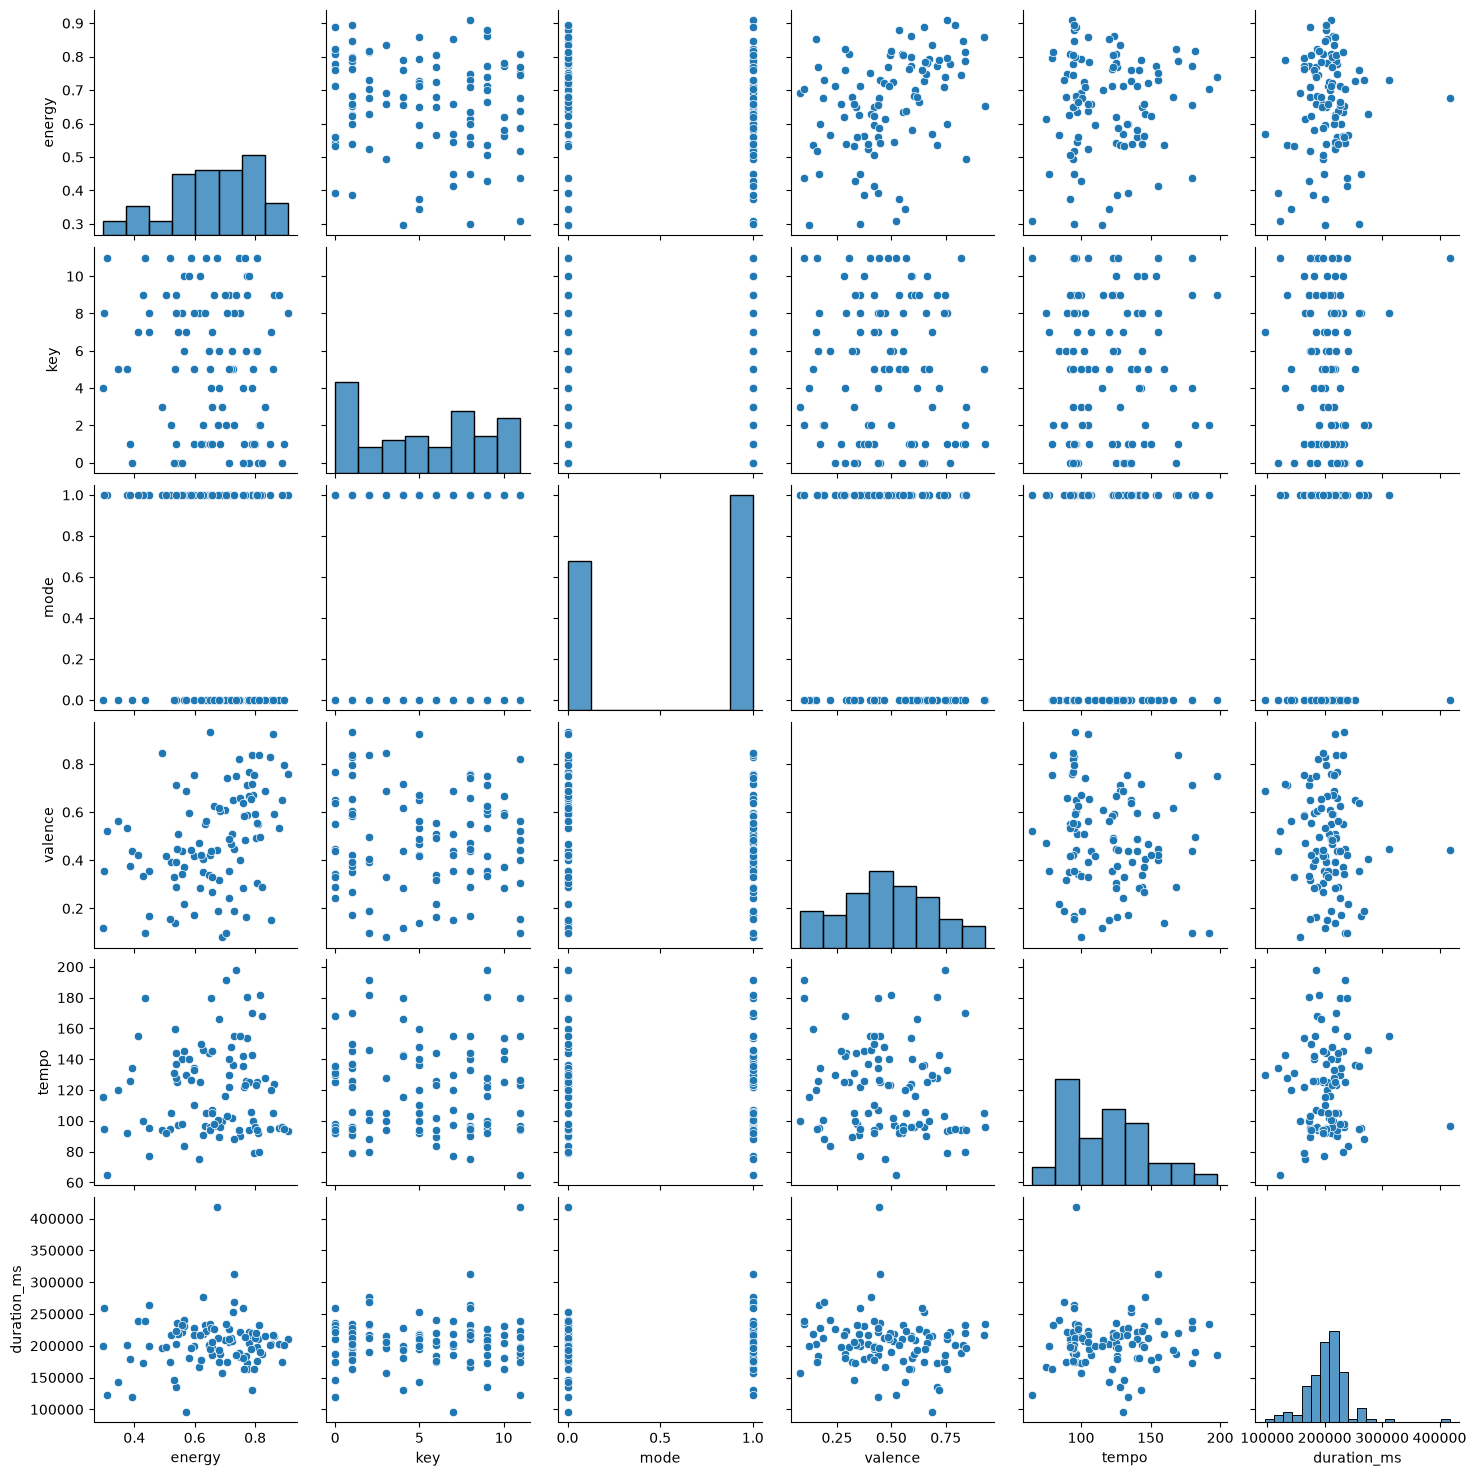

In [9]:
# Create a pair plot
sns.pairplot(df_spotify_songs)

In [10]:
#Answer
#Normal Distributions: Valence, Duration_Ms
#Other Distributions: Mode, Key(Uniform)
#Skewed Fields: Energy(Right Skew), Tempo(Left Skew), Tempo(Left Skew)

<Axes: xlabel='duration_ms', ylabel='Count'>

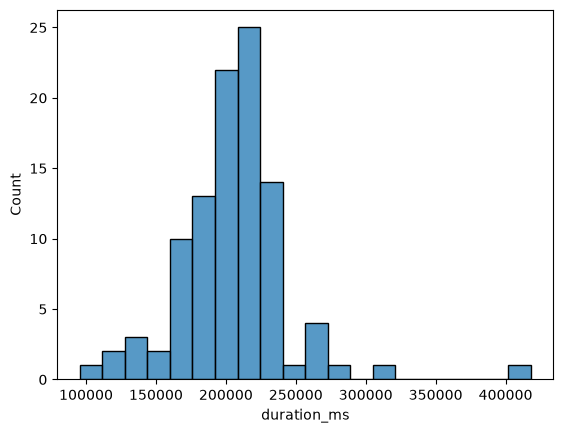

In [11]:
#Outliers
sns.histplot(df_spotify_songs['duration_ms'])

In [12]:
df_spotify_songs.loc[df_spotify_songs['duration_ms'] > 400000]

,name,artists,energy,key,mode,valence,tempo,duration_ms
21,Te Bot? - Remix,Nio Garcia,0.675,11,0,0.442,96.507,417920


<Axes: xlabel='tempo', ylabel='Count'>

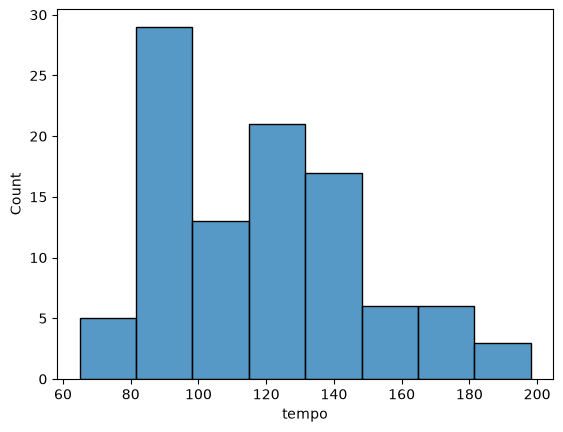

In [13]:
#Lets look closer at Tempo to understand the left Skew
sns.histplot(df_spotify_songs['tempo'])

In [14]:
#Turn it into a Frequency table and sort it out to understand better, if we round to -1, we see the spikes
df_spotify_songs['tempo'].round(-1).value_counts().sort_index()

tempo
60.0      1
80.0      5
90.0     16
100.0    19
110.0     6
120.0    12
130.0    12
140.0    10
150.0     7
160.0     3
170.0     3
180.0     4
190.0     1
200.0     1
Name: count, dtype: int64

## Correlations

Hi again,

Thanks for looking into those distributions earlier. Can you also tell us more about the correlations of the musical attributes?
Can you tell us about any relationships you can find in the data between the attributes, like if some are positively or negatively correlated?

Thanks!\
Sarah

### Interpret the scatter plots

[Musical attribute definitions](https://developer.spotify.com/documentation/web-api/reference/get-audio-features)

* Highly correlated: 
* Uncorrelated: 
* Positive correlation: 
* Negative correlation: 
* Other observations: 
* Do your interpretations make sense?

In [18]:
df_spotify_songs.head(2)

,name,artists,energy,key,mode,valence,tempo,duration_ms
0,God's Plan,Drake,0.449,7,1,0.357,77.169,198973
1,SAD!,XXXTENTACION,0.613,8,1,0.473,75.023,166606


In [19]:
#Evaluate correlations
df_spotify_songs[['energy', 'key', 'mode', 'valence', 'tempo', 'duration_ms']].corr()

,energy,key,mode,valence,tempo,duration_ms
energy,1.000000,-0.136345,-0.117555,0.382434,0.062272,0.073017
key,-0.136345,1.000000,-0.141568,-0.032622,0.003737,0.046144
mode,-0.117555,-0.141568,1.000000,-0.210599,-0.011911,0.055411
valence,0.382434,-0.032622,-0.210599,1.000000,-0.148423,-0.131901
tempo,0.062272,0.003737,-0.011911,-0.148423,1.000000,0.005493
duration_ms,0.073017,0.046144,0.055411,-0.131901,0.005493,1.000000


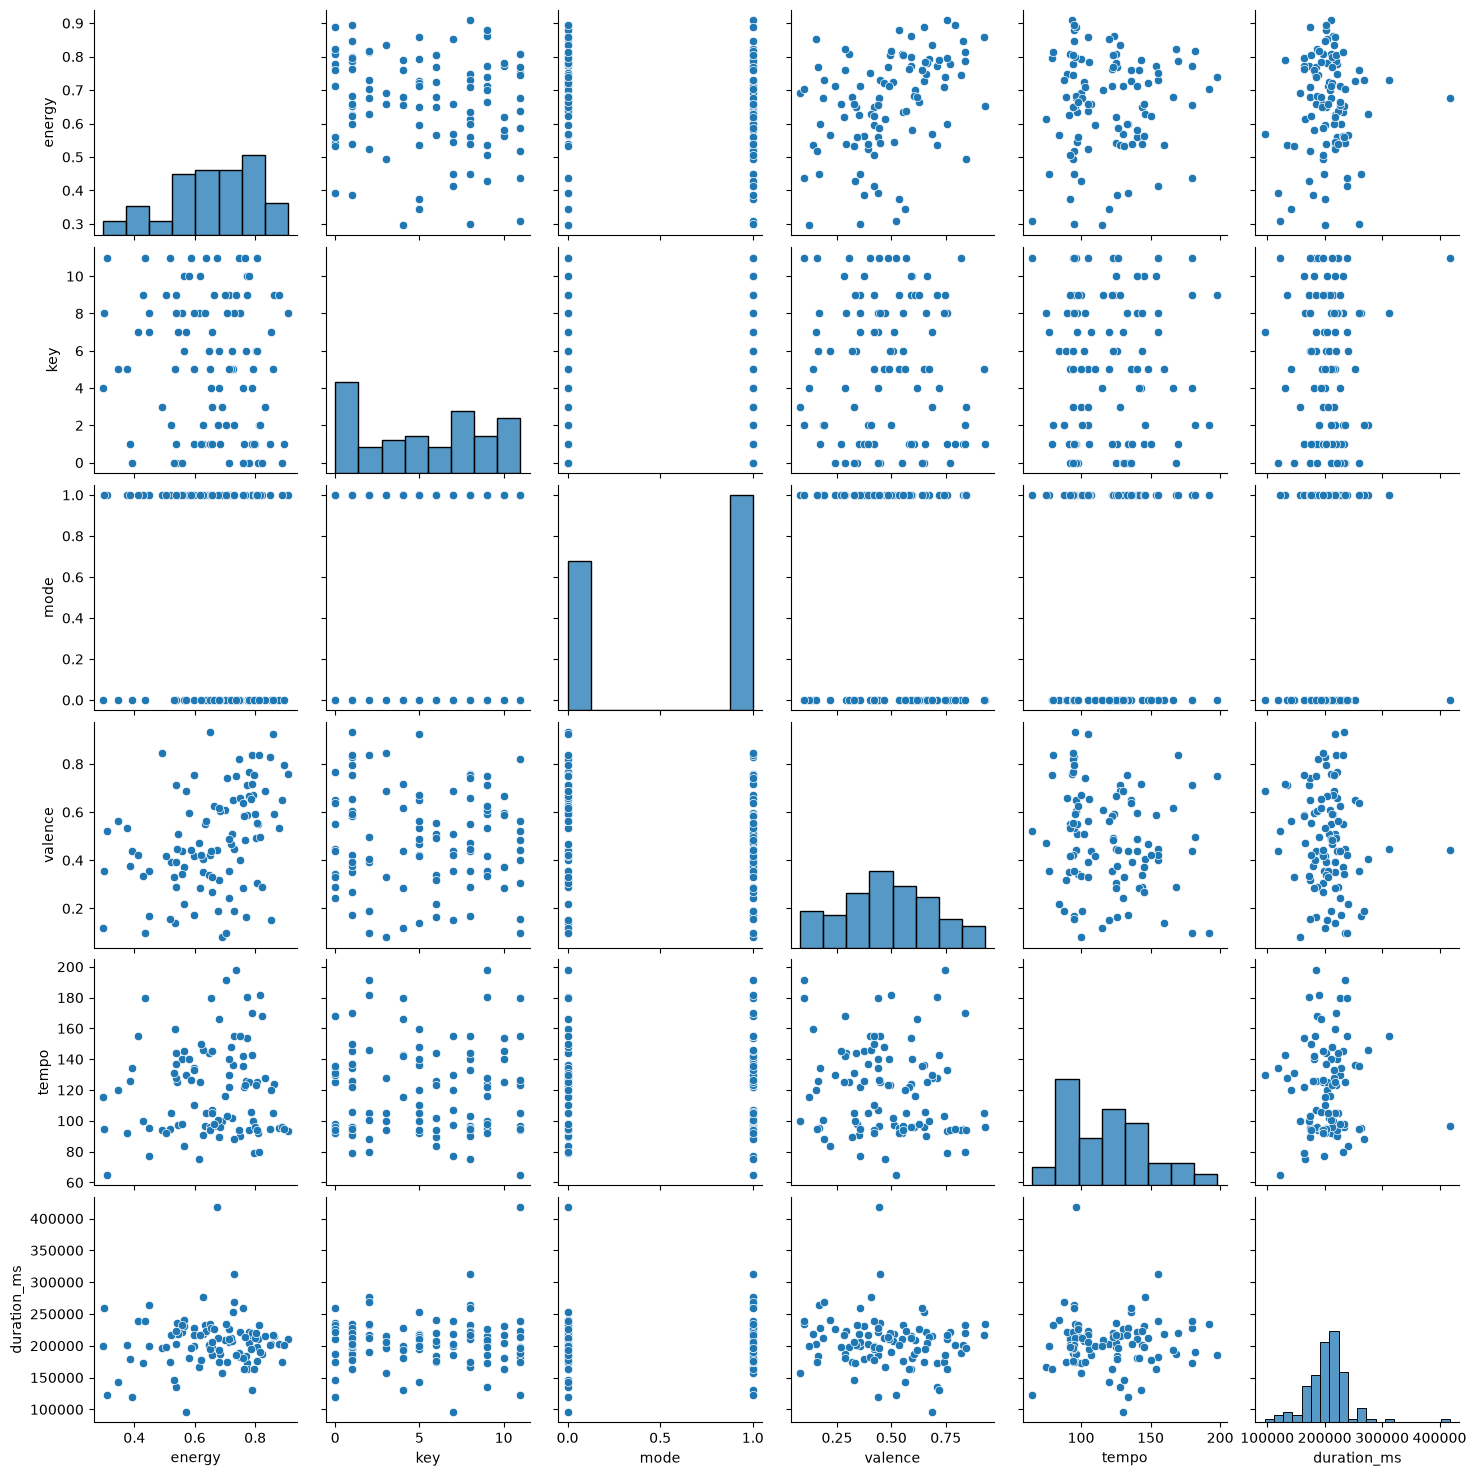

In [21]:
sns.pairplot(df_spotify_songs)

In [ ]:
### Interpret the scatter plots

[Musical attribute definitions](https://developer.spotify.com/documentation/web-api/reference/get-audio-features)

* Highly correlated: none
* Uncorrelated(+-0.05): Key vs Valence, Key vs Tempo, Key vs duration_ms, Tempo vs Mode, Tempo vs Duration_ms
* Positive correlation: Energy vs Valence, Energy vs Tempo, Energy vs Duration_ms, mode vs Duration_ms
* Negative correlation: Energy vs Key, Energy vs Mode, Mode vs Valence, Valence vs Tempo, Duration_ms vs Valence, Key vs Mode
* Other observations: Duration_ms has outliers, Key vs Mode are Discrete values